# Phase 1: Supervised Learning — Customer Churn

## 1. Model Selection & Rationale

### 1.1 Problem Type and Dataset Summary
We are predicting whether a customer will churn. This is a binary classification task (`churn_flag`: 1 = churned, 0 = retained).

The dataset has 100,000 rows and 18 columns. We removed `customer_id` because it is only an identifier. We also removed `churn_risk` because it is built from the target. High always means churned and Low always means retained, so keeping it would leak the answer. That leaves 15 predictors: 10 numeric and 5 categorical.

Part A found no missing values. The classes are fairly balanced: 46.22% churned and 53.78% retained.


### 1.2 Logistic Regression

We chose Logistic Regression as one of our classification models because it is simple, interpretable, and suitable for binary classification. It also estimates the probability that a customer will churn.

Our analysis in Part A supports this choice. The dataset contains 100,000 customer records, with a relatively balanced class distribution: 46.22% churned customers and 53.78% retained customers.

Strengths:

Logistic Regression is computationally efficient, making it suitable for handling our dataset size. Its results are also easy to interpret through feature coefficients, which help us understand the factors associated with customer churn. Additionally, it provides a churn probability for each customer, helping the company identify customers at higher risk of leaving and prioritize retention efforts.

Weaknesses:

Logistic Regression assumes a linear relationship between customer features and the log-odds of churn. Therefore, it may struggle to capture complex nonlinear relationships and interactions between different customer behaviors, which could limit its ability to represent certain complex churn patterns.


#### 1.3 Random Forest Classifier

We chose Random Forest to test whether a more flexible model does better, and it is suitable for our binary classification task because it can predict whether a customer will churn or stay. It can learn non-linear patterns and feature interactions, 

our dataset contains 100000 customers, with 10 numerical and 5 categorical features. Random forest is suitable for this dataset because it can handle large datasets and work well with a mix of numeric and encoded categorical features. 

Random forest has several strengths, It does not need scaling and is less sensitive to skewed features, and its performance is generally not affected by scaling because it uses decision trees
It also gives feature importance scores, which helps us see which factors have significant impact on predicting the churn.

The trade-off is that it is harder to explain than Logistic Regression because it combines predictions from muliple decision trees, and slower to train especially when using large number of trees.

### 1.4 Why This Pair
Logistic Regression is the simple, interpretable baseline. Random Forest is the flexible model. We will compare them on the same data split with the same metrics. This will show whether the extra complexity is worth it for this problem.

## 2. Implementation & Training Code

In [1]:
import pandas as pd

# Load the processed training and testing datasets from Part A
train = pd.read_csv("Dataset/Processed/train_processed.csv")
test = pd.read_csv("Dataset/Processed/test_processed.csv")

# Display dataset dimensions
print("Training data:", train.shape)
print("Testing data:", test.shape)

# Preview the training data
train.head()

Training data: (80000, 31)
Testing data: (20000, 31)


,categorical__age_group_18-24,categorical__age_group_25-34,categorical__age_group_35-44,categorical__age_group_45-54,categorical__age_group_55+,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__region_Central,categorical__region_East,...,numerical__avg_order_value,numerical__total_spent,numerical__recency_days,numerical__website_visits,numerical__discount_usage_rate,numerical__email_open_rate,numerical__cart_abandonment_rate,numerical__loyalty_score,numerical__engagement_score,churn_flag
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,-0.761699,-0.606332,-1.584302,-0.565563,-0.396897,0.471760,-0.266327,-0.058059,0.527209,0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,-0.638620,-0.234016,-1.422761,-0.005819,0.155764,-0.547079,-1.480694,1.135398,0.616482,0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,-1.317743,-0.507178,-0.444010,-0.234805,0.432095,1.327584,-0.353068,-1.713498,1.211637,0
3,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,-0.426651,-0.431940,0.173648,-0.412905,0.938701,0.757035,0.297486,-0.866529,0.348663,1
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,-1.622068,-0.661917,-0.634059,-0.654613,-0.489007,1.694366,0.470966,-1.559504,0.914059,0


In [2]:
# Separate features and target

X_train = train.drop(columns=["churn_flag"])
y_train = train["churn_flag"]

X_test = test.drop(columns=["churn_flag"])
y_test = test["churn_flag"]

# Display the dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (80000, 30)
y_train: (80000,)
X_test: (20000, 30)
y_test: (20000,)


In [3]:
print("Features used for training:")
print(X_train.columns.tolist())

Features used for training:
['categorical__age_group_18-24', 'categorical__age_group_25-34', 'categorical__age_group_35-44', 'categorical__age_group_45-54', 'categorical__age_group_55+', 'categorical__gender_Female', 'categorical__gender_Male', 'categorical__gender_Other', 'categorical__region_Central', 'categorical__region_East', 'categorical__region_North', 'categorical__region_South', 'categorical__region_West', 'categorical__customer_segment_Loyal', 'categorical__customer_segment_New', 'categorical__customer_segment_Returning', 'categorical__customer_segment_VIP', 'categorical__preferred_channel_In-Store', 'categorical__preferred_channel_Mobile App', 'categorical__preferred_channel_Online', 'numerical__purchase_frequency', 'numerical__avg_order_value', 'numerical__total_spent', 'numerical__recency_days', 'numerical__website_visits', 'numerical__discount_usage_rate', 'numerical__email_open_rate', 'numerical__cart_abandonment_rate', 'numerical__loyalty_score', 'numerical__engagement_

### 2.1 Logistic Regression – Training and Baseline Evaluation

In [4]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model تحسين اجابة الموديل
lr_model = LogisticRegression(max_iter=1000)

# Train the model using processed training data  دربته باستخدام ال 30 فيتشر و الاجابه لن موديل ترين
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [5]:
# Predict customer churn using the test data هنا للتيست توقع
y_pred = lr_model.predict(X_test)# عطيته بيانات 20 بدون الاجابه

# Display the first 10 predictions
print("Predicted:", y_pred[:10])# الي هو توقعهم
print("Actual:   ", y_test.iloc[:10].values)# الاجابات الصحيحيه في تيتسنق

Predicted: [1 0 0 0 0 1 1 1 0 0]
Actual:    [1 0 0 0 0 1 1 1 0 0]


In [6]:
from sklearn.metrics import (
    accuracy_score,# يقيس  نسبه التةقع بشكل عام الي بيطلعون او بيتسمرون صحيحه ام لا 
    precision_score,#نركز على دقه الكستوميز الي صدق توقع الموديل انهم بيطلعون
    recall_score,# هنا صدق الي طلعو فعلا  هل توقع ام لا 
    f1_score,# هنا يشوف توقعه مع الي طلعو فعلا
    roc_auc_score# ال طلعو وال مستمرين
)

# Predict churn probabilities
y_prob = lr_model.predict_proba(X_test)[:, 1]# هنا المودل المدرب بيتوقع  20 الف   بعدين بس بياخذ الي طلعو 1 مغادرين ويخزنه

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)# بيقارن 20 المتوقع مع الاجابه الحقيقه
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Logistic Regression - Baseline Results")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Logistic Regression - Baseline Results
Accuracy:  0.9459
Precision: 0.9419
Recall:    0.9410
F1-score:  0.9415
ROC-AUC:   0.9904


### 2.2 Random Forest – Training and Baseline Evaluation

In [7]:
#Model 2 - Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Create Random Forest Pipeline
rf_pipeline = Pipeline(
    steps=[
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=1
        ))
    ]
)

#Train Random Forest model
rf_pipeline.fit(X_train,y_train)

#print confirmation
print("Random Forest trained successfully!")

Random Forest trained successfully!


In [8]:
#Model 2 - Random Forest

#Predict customer churn
rf_y_pred = rf_pipeline.predict(X_test)

#Display the first 15 predictions
print("Predicted:",rf_y_pred[:15])
print("Actual:",y_test.iloc[:15].values)

Predicted: [0 1 0 0 0 1 1 1 0 0 1 0 0 0 0]
Actual: [1 0 0 0 0 1 1 1 0 0 1 0 0 0 0]


In [9]:
#Model 2 - Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predicted churn probabilities
rf_y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
rf_accuracy = accuracy_score(y_test, rf_y_pred)
rf_precision = precision_score(y_test, rf_y_pred)
rf_recall = recall_score(y_test, rf_y_pred)
rf_f1 = f1_score(y_test, rf_y_pred)
rf_roc_auc = roc_auc_score(y_test, rf_y_prob)

# Display results
print("Random Forest - Baseline Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Random Forest - Baseline Results
Accuracy: 0.9421
Precision: 0.9389
Recall: 0.9355
F1-score: 0.9372
ROC-AUC: 0.988


# 3. Hyperparameter Tuning Process & Results

### 3.1 Logistic Regression – Hyperparameter Tuning

In [10]:
import pandas as pd
#  وهو مفيد لتحسين الاداء:هنا رجعنا جربنا اعدادات مختلفه وبندرب الموديل على 64 الف وليس 80 عشان ماصيصير داتا ليكج
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler# نوحد المقايس الرقميه بلس نحول اي شي  كتابه الى اقام 
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Load training data before preprocessing
lr_train_selected = pd.read_csv(
    "Dataset/Processed/train_selected.csv"
)

# Separate features and target
lr_X_train = lr_train_selected.drop(columns=["churn_flag"])# كل 15
lr_y_train = lr_train_selected["churn_flag"] # الانسر

# Identify numerical and categorical features
lr_numerical_features = lr_X_train.select_dtypes(
    include=["number"]
).columns.tolist()

lr_categorical_features = lr_X_train.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

# Define preprocessing steps
lr_preprocessing_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), lr_numerical_features),# للاعمده الرقميه 
        ("cat", OneHotEncoder(handle_unknown="ignore"),# للتحويل من نصوص لرقم
         lr_categorical_features)
    ]
)
# هنا  سوينا البايب لاين عشان يحافظ انه يمشي على شكل ستيبس بكل  جوله 
# Create Logistic Regression Pipeline
lr_cv_pipeline = Pipeline(
    steps=[
        ("preprocessing", lr_preprocessing_cv),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

# Define hyperparameter values
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["lbfgs", "liblinear"]
}

# Define 5-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,# نقسم 80 الف على خمسه
    shuffle=True,# نخلط ترتيب الكوستمرز 
    random_state=42
)

# Perform Hyperparameter Tuning
grid_search = GridSearchCV(
    estimator=lr_cv_pipeline,
    param_grid=param_grid,# الاعدادات  ال 8 الي بنجربها 
    scoring="f1",# هذا مقياس الي بيحدد ايهم احسن من 8
    cv=cv,#  بنجرب 8 لكل جوله40 
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(lr_X_train, lr_y_train)

# Display the results
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.01, 'model__solver': 'lbfgs'}
Best CV F1-score: 0.9395


In [11]:
# Model 2 - Random Forest
# 5-Fold Cross-Validation

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


############# importing selected data and preparing the pipeline #############


# Load selected training data before preprocessing (to prevent data leakage)
rf_train_selected = pd.read_csv(
    "Dataset/Processed/train_selected.csv"
)

# Separate features and target
rf_X_train = rf_train_selected.drop(columns=["churn_flag"])
rf_y_train = rf_train_selected["churn_flag"]

# Identify feature types
rf_numerical_features = rf_X_train.select_dtypes(
    include=["number"]
).columns.tolist()

rf_categorical_features = rf_X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing inside the Pipeline
rf_preprocessing_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), rf_numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         rf_categorical_features)
    ]
)

# Random Forest Pipeline for Cross-Validation
rf_cv_pipeline = Pipeline(
    steps=[
        ("preprocessing", rf_preprocessing_cv),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=1
        ))
    ]
)

###################################################################


# Hyperparameter grid (defining possible parameters combination)
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5]
}

# 5-Fold stratified Cross-Validation to maintain class proportions
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for best hyperparameters based on F1
rf_grid_search = GridSearchCV(
    estimator=rf_cv_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

# Run tuning
rf_grid_search.fit(rf_X_train, rf_y_train)

# Display results
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV F1-score:", round(rf_grid_search.best_score_, 4))


Fitting 5 folds for each of 12 candidates, totalling 60 fits


C:\Users\albrh\AppData\Local\Temp\ipykernel_16276\3058612984.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  rf_categorical_features = rf_X_train.select_dtypes(


Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best CV F1-score: 0.9347


### 3.3 Hyperparameter Tuning Discussion

F1-score was selected as the evaluation metric for hyperparameter tuning because it balances precision and recall. This is important in customer churn prediction, where both identifying customers at risk of leaving and reducing false positive predictions are valuable.

#### Logistic Regression

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. Preprocessing was included within a Pipeline to prevent data leakage between validation folds.

The best parameters were C = 0.01 and solver = lbfgs, achieving a mean cross-validation F1-score of 0.9395.

#### Random Forest

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. Preprocessing was included within a Pipeline to prevent data leakage between validation folds.

The best parameters were n_estimators = 200, max_depth = None, and min_samples_split = 2, achieving a mean cross-validation F1-score of 0.9347.

These parameters were selected based on the highest mean F1-score across the five validation folds.

## 4. Evaluation Metrics & Visualizations

In [12]:
# Model 1 - Logistic Regression
# Tuned Model Evaluation

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load selected test data before preprocessing
lr_test_selected = pd.read_csv(
    "Dataset/Processed/test_selected.csv"
)

# Separate features and target
lr_X_test = lr_test_selected.drop(columns=["churn_flag"])# العشرين الف بدون الاجابات
lr_y_test = lr_test_selected["churn_flag"]# الاجابات

# Get the best tuned Logistic Regression model
best_lr_model = grid_search.best_estimator_# المودل الي فاز قبل شوي جب معلوماته

# Make predictions
y_pred_tuned = best_lr_model.predict(lr_X_test)#توقع لل 20 الف 0و1 بيطلعون ولا لا
y_prob_tuned = best_lr_model.predict_proba(lr_X_test)[:, 1]# خذ الي  احتمال يغادرون

# Calculate evaluation metrics
tuned_accuracy = accuracy_score(lr_y_test, y_pred_tuned)# مقارنه بين توقع و الحقيقه
tuned_precision = precision_score(lr_y_test, y_pred_tuned)
tuned_recall = recall_score(lr_y_test, y_pred_tuned)
tuned_f1 = f1_score(lr_y_test, y_pred_tuned)
tuned_roc_auc = roc_auc_score(lr_y_test, y_prob_tuned)

# Display results
print("Logistic Regression - Tuned Results")
print(f"Accuracy:  {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall:    {tuned_recall:.4f}")
print(f"F1-score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_roc_auc:.4f}")

Logistic Regression - Tuned Results
Accuracy:  0.9455
Precision: 0.9418
Recall:    0.9401
F1-score:  0.9409
ROC-AUC:   0.9904


### Logistic Regression - Baseline vs Tuned Comparison

The baseline Logistic Regression model achieved slightly better performance than the tuned model.

Accuracy decreased from 0.9459 to 0.9455, precision from 0.9419 to 0.9418, recall from 0.9410 to 0.9401, and F1-score from 0.9415 to 0.9409.

ROC-AUC remained approximately unchanged at 0.9904.

Overall, hyperparameter tuning did not improve Logistic Regression's performance on the test set. However, the differences were very small, indicating that both configurations performed similarly.



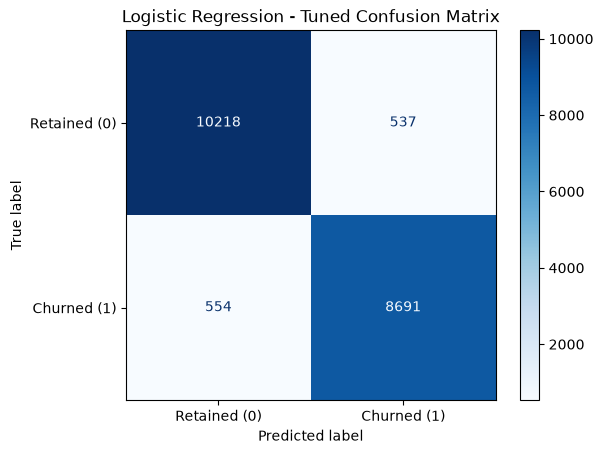

In [13]:
# Model 1 - Logistic Regression

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion Matrix for Tuned Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    lr_y_test,
    y_pred_tuned,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Tuned Confusion Matrix")

plt.savefig(
    "Supervised_Learning/plots/lr_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


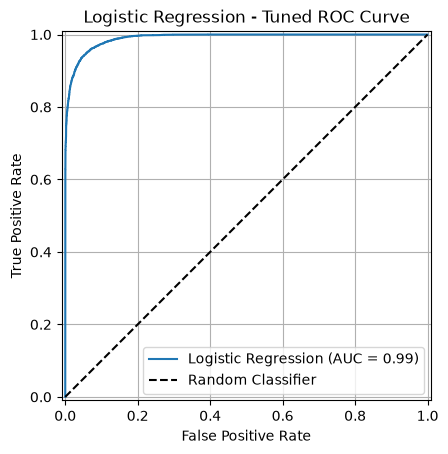

In [14]:
# Model 1 - Logistic Regression

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Logistic Regression
RocCurveDisplay.from_predictions(
    lr_y_test,
    y_prob_tuned,
    name="Logistic Regression"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Logistic Regression - Tuned ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.savefig(
    "Supervised_Learning/plots/lr_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

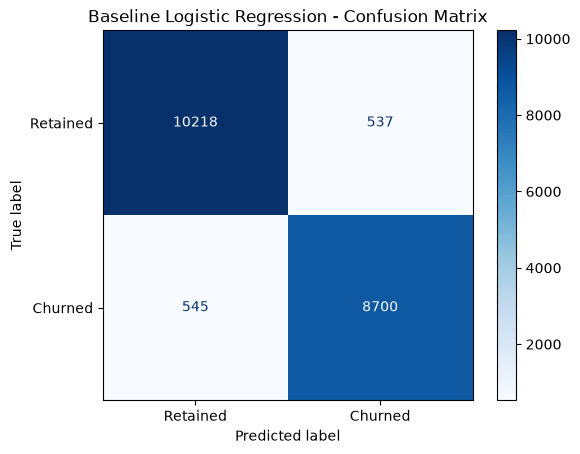

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Baseline Logistic Regression - Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.savefig(
    "Supervised_Learning/plots/lr_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

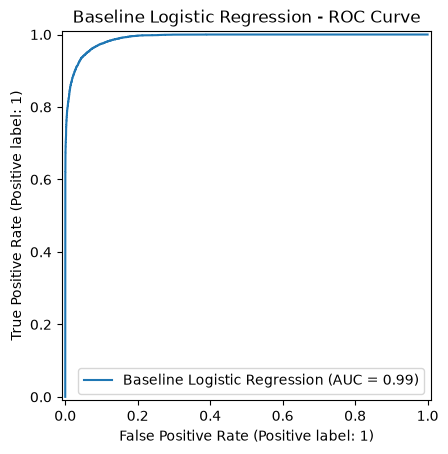

In [24]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Baseline Logistic Regression - ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Baseline Logistic Regression"
)

plt.title("Baseline Logistic Regression - ROC Curve")
plt.savefig(
    "Supervised_Learning/plots/lr_baseline_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [15]:
#Model 2 - Random Forest

# Load selected test data before preprocessing
rf_test_selected = pd.read_csv(
    "Dataset/Processed/test_selected.csv"
)

# Separate features and target
rf_X_test = rf_test_selected.drop(columns=["churn_flag"])
rf_y_test = rf_test_selected["churn_flag"]

# Get the best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# Make predictions
rf_tuned_pred = rf_tuned_model.predict(rf_X_test)
rf_tuned_prob = rf_tuned_model.predict_proba(rf_X_test)[:, 1]

# Calculate metrics
rf_tuned_accuracy = accuracy_score(rf_y_test, rf_tuned_pred)
rf_tuned_precision = precision_score(rf_y_test, rf_tuned_pred)
rf_tuned_recall = recall_score(rf_y_test, rf_tuned_pred)
rf_tuned_f1 = f1_score(rf_y_test, rf_tuned_pred)
rf_tuned_roc_auc = roc_auc_score(rf_y_test, rf_tuned_prob)

# Display results
print("Random Forest - Tuned Results")
print("Accuracy:", round(rf_tuned_accuracy, 4))
print("Precision:", round(rf_tuned_precision, 4))
print("Recall:", round(rf_tuned_recall, 4))
print("F1-score:", round(rf_tuned_f1, 4))
print("ROC-AUC:", round(rf_tuned_roc_auc, 4))


Random Forest - Tuned Results
Accuracy: 0.9424
Precision: 0.9387
Recall: 0.9365
F1-score: 0.9376
ROC-AUC: 0.9882


### Random Forest - Baseline vs Tuned Comparison

The tuned Random Forest model achieved slightly better performance than the baseline model in four out of five evaluation metrics.

Accuracy increased from 0.9421 to 0.9424, recall from 0.9355 to 0.9365, F1-score from 0.9372 to 0.9376, and ROC-AUC from 0.9880 to 0.9882.

However, precision decreased slightly from 0.9389 to 0.9387.

Overall, hyperparameter tuning was associated with a small improvement in performance, particularly in recall, which is important for identifying customers at risk of churn.

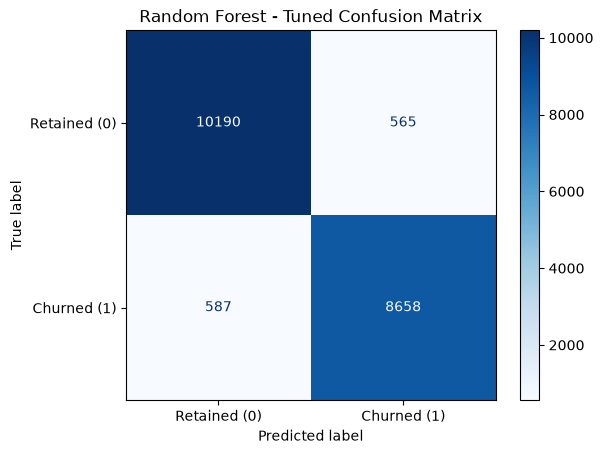

In [16]:
# Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create Confusion Matrix for Tuned Random Forest
ConfusionMatrixDisplay.from_predictions(
    rf_y_test,
    rf_tuned_pred,
    display_labels=["Retained (0)", "Churned (1)"],
    cmap="Blues",
    values_format="d"
)

#define title
plt.title("Random Forest - Tuned Confusion Matrix")

plt.savefig(
    "Supervised_Learning/plots/rf_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

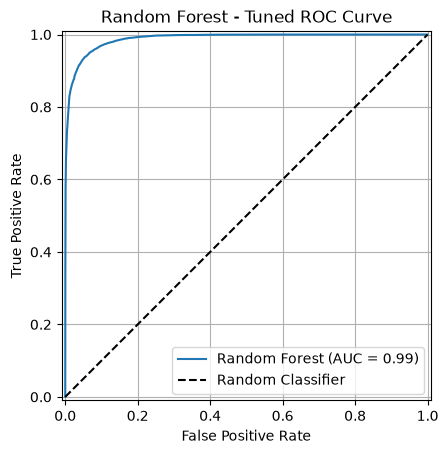

In [17]:
# Model 2 - Random Forest

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot ROC Curve for Tuned Random Forest
RocCurveDisplay.from_predictions(
    rf_y_test,
    rf_tuned_prob,
    name="Random Forest"
)

# Random classifier reference line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("Random Forest - Tuned ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

# Save ROC Curve
plt.savefig(
    "Supervised_Learning/plots/rf_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

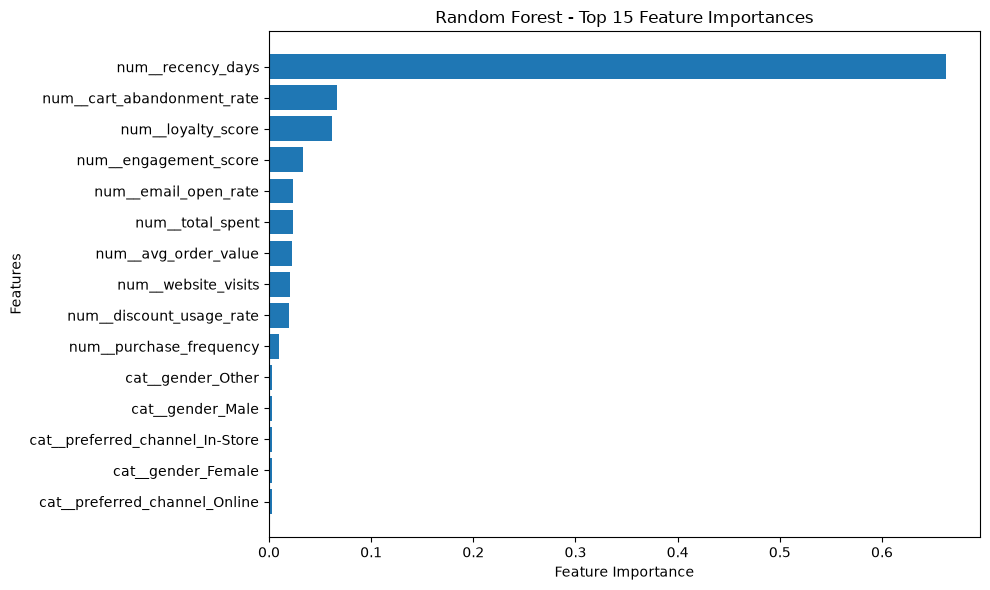

In [18]:
# Model 2 - Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# best tuned Random Forest model
rf_tuned_model = rf_grid_search.best_estimator_

# feature names after preprocessing
rf_feature_names = rf_tuned_model.named_steps[
    "preprocessing"
].get_feature_names_out()

# feature importance scores
rf_importances = rf_tuned_model.named_steps[
    "model"
].feature_importances_

# Create DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Select the top 15 most important features
rf_top_15 = rf_importance_df.nlargest(
    15, "Importance"
).sort_values("Importance")

# Plot Feature Importance
plt.figure(figsize=(10, 6))
plt.barh(rf_top_15["Feature"], rf_top_15["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importances")
plt.tight_layout()
plt.savefig(
    "Supervised_Learning/plots/rf_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Misclassification Analysis



The tuned **Logistic Regression** model incorrectly classified 1,091 out of 20,000 customers.

- False Positives (537): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (554): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.



The tuned **Random Forest** model misclassified 1152 out of 20000 customers, achieving an accuracy of 94.24%.

- False Positives (565): Customers predicted to churn who actually stayed. This may lead to unnecessary retention offers.
- False Negatives (587): Customers predicted to stay who actually churned. This is particularly important because the business may miss opportunities to retain these customers.

Compared with Logistic Regression, which misclassified 1,091 customers, Random Forest made 61 more classification errors.

For our customer retention system, reducing false negatives is valuable because identifying customers at risk of churn allows the business to take preventive actions.

### ROC Curve Analysis

Both Logistic Regression and Random Forest achieved high ROC-AUC scores, indicating strong ability to distinguish between churned and retained customers.

Logistic Regression achieved a ROC-AUC of 0.9904, slightly higher than Random Forest's 0.9882.

### ROC Curve Analysis Feature Importance Analysis - Random Forest

The Random Forest feature importance plot shows that recency_days is the most influential feature in predicting customer churn, with a substantially higher importance score than the other features.

cart_abandonment_rate and loyalty_score are the next most important features, followed by engagement_score and email_open_rate.

These results suggest that recent customer activity, shopping behavior, and loyalty are important factors in the model's churn predictions.

Categorical features, such as gender and preferred channel, have relatively low individual importance scores.


## 5. Model Comparison & Analysis

In [25]:
import pandas as pd

# Compare Baseline LR, Tuned LR, and Tuned RF
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Baseline Logistic Regression": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],

    "Tuned Logistic Regression": [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ],

    "Tuned Random Forest": [
        rf_tuned_accuracy,
        rf_tuned_precision,
        rf_tuned_recall,
        rf_tuned_f1,
        rf_tuned_roc_auc
    ]
})

display(comparison.round(4))

,Metric,Baseline Logistic Regression,Tuned Logistic Regression,Tuned Random Forest
0,Accuracy,0.9459,0.9454,0.9424
1,Precision,0.9419,0.9418,0.9387
2,Recall,0.9410,0.9401,0.9365
3,F1-score,0.9415,0.9409,0.9376
4,ROC-AUC,0.9904,0.9904,0.9882


In [26]:
import pandas as pd
import numpy as np

# Misclassification Analysis by Customer Segment
# Baseline Logistic Regression vs Tuned Random Forest

# Load test data
error_analysis = pd.read_csv("Dataset/Processed/test_selected.csv")

# Check that predictions match the test data
assert len(error_analysis) == len(y_pred) == len(rf_tuned_pred)

assert np.array_equal(
    error_analysis["churn_flag"].to_numpy(),
    np.asarray(y_test)
), "Test labels do not match."

# Identify incorrect predictions for both models
error_analysis["LR_Error"] = (
    y_pred != error_analysis["churn_flag"].to_numpy()
).astype(int)

error_analysis["RF_Error"] = (
    rf_tuned_pred != error_analysis["churn_flag"].to_numpy()
).astype(int)

# Calculate errors by customer segment
segment_errors = error_analysis.groupby("customer_segment").agg(
    Total_Customers=("churn_flag", "size"),
    LR_Errors=("LR_Error", "sum"),
    RF_Errors=("RF_Error", "sum"),
    LR_Error_Rate=("LR_Error", "mean"),
    RF_Error_Rate=("RF_Error", "mean")
)

# Convert error rates to percentages
segment_errors["LR_Error_Rate"] = (
    segment_errors["LR_Error_Rate"] * 100
).round(2)

segment_errors["RF_Error_Rate"] = (
    segment_errors["RF_Error_Rate"] * 100
).round(2)

display(segment_errors)

,Total_Customers,LR_Errors,RF_Errors,LR_Error_Rate,RF_Error_Rate
customer_segment,,,,,
Loyal,4957,262,291,5.29,5.87
New,5137,304,309,5.92,6.02
Returning,5017,275,285,5.48,5.68
VIP,4889,241,267,4.93,5.46


In [31]:
import time
from sklearn.base import clone

# Create a new copy of the tuned Random Forest pipeline
rf_timing_model = clone(rf_grid_search.best_estimator_)

# Measure training time
start = time.perf_counter()
rf_timing_model.fit(rf_X_train, rf_y_train)
rf_training_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()
rf_timing_model.predict(rf_X_test)
rf_prediction_time = time.perf_counter() - start

#print training/prediction time result
print(f"Random Forest Training Time: {rf_training_time:.4f} seconds")
print(f"Random Forest Prediction Time: {rf_prediction_time:.4f} seconds")

Random Forest Training Time: 17.8112 seconds
Random Forest Prediction Time: 0.4957 seconds


In [30]:
import time
from sklearn.base import clone

# Create a fresh copy of the baseline Logistic Regression model
lr_timing_model = clone(lr_model)

# Measure training time
start = time.perf_counter()
lr_timing_model.fit(X_train, y_train)
lr_training_time = time.perf_counter() - start

# Measure prediction time
start = time.perf_counter()
lr_timing_model.predict(X_test)
lr_prediction_time = time.perf_counter() - start

# Display training and prediction times
print(f"Baseline Logistic Regression Training Time: {lr_training_time:.4f} seconds")
print(f"Baseline Logistic Regression Prediction Time: {lr_prediction_time:.4f} seconds")

Baseline Logistic Regression Training Time: 0.1093 seconds
Baseline Logistic Regression Prediction Time: 0.0058 seconds


### Model Comparison & Analysis

Both Logistic Regression and Random Forest achieved strong performance in predicting customer churn. The comparison included three model configurations: **Baseline Logistic Regression, Tuned Logistic Regression, and Tuned Random Forest**.

The Baseline Logistic Regression achieved the highest accuracy of **0.9459**, followed by Tuned Logistic Regression at 0.9455 and Tuned Random Forest at 0.9424.

Similarly, Baseline Logistic Regression achieved the highest precision (0.9419), recall (0.9410), and F1-score (0.9415). The ROC-AUC scores were approximately 0.9904 for both Logistic Regression configurations, compared with 0.9882 for Tuned Random Forest.

Although hyperparameter tuning was applied to Logistic Regression, it did not improve its performance on the test dataset. The baseline model achieved slightly better results across the main classification metrics.

Overall, Logistic Regression consistently outperformed Random Forest, while the differences between the models remained relatively small.

### Misclassification Patterns and Challenges

The misclassification analysis compared **Baseline Logistic Regression and Tuned Random Forest** across four customer segments: Loyal, New, Returning, and VIP.

Baseline Logistic Regression achieved lower misclassification rates than Tuned Random Forest across all four customer segments.

The **New** customer segment had the highest error rates for both models (5.92% for Baseline Logistic Regression and 6.02% for Tuned Random Forest), indicating that this segment was relatively more challenging to classify.

In contrast, the **VIP** segment had the lowest error rates (4.93% for Baseline Logistic Regression and 5.46% for Tuned Random Forest).

These findings further support the selection of Baseline Logistic Regression, as it demonstrated slightly more consistent performance across customer segments.

### Interpretability Analysis

Logistic Regression is easier to **interpret** because its coefficients help explain how different features influence churn predictions.

In contrast, Random Forest uses multiple decision trees, making individual predictions more difficult to explain. However, its feature importance scores help identify which features contribute most to the model's predictions.

Therefore, Logistic Regression offers an advantage in interpretability, which is valuable for understanding the factors associated with customer churn.

### Computational Cost Analysis

The recorded training and prediction times were 0.1645 seconds and 0.0181 seconds for Logistic Regression, compared with 15.5328 seconds and 0.4746 seconds for Random Forest, respectively.

These measurements indicate that Logistic Regression was more computationally efficient in the recorded experiment.

This difference is expected because Logistic Regression is a simpler model, whereas Random Forest combines multiple decision trees, increasing its computational cost.

However, these timing results should be interpreted according to the specific model configurations used during measurement. Execution times may also vary depending on the hardware and system conditions.

### Final Model Recommendation

Based on the evaluation results, **Baseline Logistic Regression is recommended as the final model** for the Customer Churn Prediction System.

Baseline Logistic Regression achieved the highest accuracy (0.9459), precision (0.9419), recall (0.9410), and F1-score (0.9415) among the three evaluated configurations.

Although hyperparameter tuning was performed, the Tuned Logistic Regression did not outperform the baseline model on the test dataset. Therefore, the baseline configuration was selected based on its slightly better predictive performance.

Additionally, Logistic Regression offers greater interpretability and demonstrated lower computational cost than Random Forest in the recorded experiment.

The misclassification analysis also showed that Baseline Logistic Regression achieved lower error rates across all four customer segments compared with Tuned Random Forest.

Although Random Forest demonstrated strong predictive performance and the ability to capture nonlinear relationships, it did not outperform Logistic Regression in this experiment.

Therefore, **Baseline Logistic Regression provides the best overall balance between predictive performance, interpretability, and computational efficiency** for this project.


## 6. Conclusion: Best Model Selection & Reasoning

### Model Comparison & Analysis

Both Logistic Regression and Random Forest achieved strong performance in predicting customer churn. The comparison included three model configurations: **Baseline Logistic Regression, Tuned Logistic Regression, and Tuned Random Forest**.

The Baseline Logistic Regression achieved the highest accuracy of **0.9459**, followed by Tuned Logistic Regression at 0.9455 and Tuned Random Forest at 0.9424.

Similarly, Baseline Logistic Regression achieved the highest precision (0.9419), recall (0.9410), and F1-score (0.9415). The ROC-AUC scores were approximately 0.9904 for both Logistic Regression configurations, compared with 0.9882 for Tuned Random Forest.

Although hyperparameter tuning was applied to Logistic Regression, it did not improve its performance on the test dataset. The baseline model achieved slightly better results across the main classification metrics.

Overall, Logistic Regression consistently outperformed Random Forest, while the differences between the models remained relatively small.

### Misclassification Patterns and Challenges

The misclassification analysis compared **Baseline Logistic Regression and Tuned Random Forest** across four customer segments: Loyal, New, Returning, and VIP.

Baseline Logistic Regression achieved lower misclassification rates than Tuned Random Forest across all four customer segments.

The **New** customer segment had the highest error rates for both models (5.92% for Baseline Logistic Regression and 6.02% for Tuned Random Forest), indicating that this segment was relatively more challenging to classify.

In contrast, the **VIP** segment had the lowest error rates (4.93% for Baseline Logistic Regression and 5.46% for Tuned Random Forest).

These findings further support the selection of Baseline Logistic Regression, as it demonstrated slightly more consistent performance across customer segments.

### Interpretability Analysis

Logistic Regression is easier to **interpret** because its coefficients help explain how different features influence churn predictions.

In contrast, Random Forest uses multiple decision trees, making individual predictions more difficult to explain. However, its feature importance scores help identify which features contribute most to the model's predictions.

Therefore, Logistic Regression offers an advantage in interpretability, which is valuable for understanding the factors associated with customer churn.

### Computational Cost Analysis

The computational cost analysis compared the training and prediction times of **Baseline Logistic Regression** and **Tuned Random Forest**.

Baseline Logistic Regression recorded a training time of **0.1093 seconds** and a prediction time of **0.0058 seconds**. In comparison, Tuned Random Forest required **17.8112 seconds** for training and **0.4957 seconds** for prediction.

These measurements indicate that Baseline Logistic Regression required substantially less execution time than Tuned Random Forest in the recorded experiment.

This difference is consistent with the computational characteristics of the models, as Logistic Regression is generally less computationally intensive, whereas Random Forest combines multiple decision trees.

However, the timing measurements were obtained using different model configurations and preprocessing setups. The Baseline Logistic Regression timing excluded preprocessing, while the Tuned Random Forest timing included preprocessing within its pipeline. Therefore, the results reflect the execution costs of the measured implementations rather than a fully controlled comparison of the two algorithms.

Additionally, the reported training time for Tuned Random Forest represents the time required to fit the selected model configuration, excluding the hyperparameter search process.

Execution times may also vary depending on hardware and system conditions.

### Final Model Recommendation

Based on the evaluation results, **Baseline Logistic Regression is recommended as the final model** for the Customer Churn Prediction System.

Baseline Logistic Regression achieved the highest accuracy (0.9459), precision (0.9419), recall (0.9410), and F1-score (0.9415) among the three evaluated configurations.

Although hyperparameter tuning was performed, the Tuned Logistic Regression did not outperform the baseline model on the test dataset. Therefore, the baseline configuration was selected based on its slightly better predictive performance.

Additionally, Logistic Regression offers greater interpretability and demonstrated lower measured execution time than Tuned Random Forest in the recorded experiment, although the timing setups were not fully equivalent.

The misclassification analysis also showed that Baseline Logistic Regression achieved lower error rates across all four customer segments compared with Tuned Random Forest.

Although Random Forest demonstrated strong predictive performance and the ability to capture nonlinear relationships, it did not outperform Logistic Regression in this experiment.

Therefore, **Baseline Logistic Regression provides the best overall balance between predictive performance, interpretability, and computational efficiency** for this project.


## 7. Next Steps for Phase 2 Integration

In Phase 2, we will use the baseline Logistic Regression model as the core of our customer churn prediction system, as it achieved slightly better evaluation results than the tuned version in Phase 1.

We will integrate the selected model into the system to predict churn probabilities for new customers and identify those who are more likely to leave, helping support customer retention decisions.

We will also apply the same preprocessing steps used during training to new customer data to ensure consistent and reliable predictions.

Finally, we will test the integrated system to verify that the model works correctly and produces reliable predictions.
